# Percobaan: Random Search

Baseline: genome diambil acak, tanpa mekanisme pencarian. Paper juga memakai random sebagai referensi.

Notebook ini juga template untuk algoritma lain: cukup ganti cell konfigurasi.

## 0. Setup

In [ ]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.paths import FIGURES_DIR, RUNS_DIR, TABLES_DIR
from src.problem import load_instances
from src.evaluation.runner import load_results, make_seeds, run_experiment
from src.evaluation.metrics import best_configs, rank_configs, runs_to_frame, save_table, summarize
from src.evaluation import plots

pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Konfigurasi

Setiap konfigurasi dijalankan pada 6 instance x `N_RUNS` seed. Seed diacak dari `MASTER_SEED`, dan daftar seed yang sama dipakai untuk semua konfigurasi.

`OPTIMUM` menentukan model data dan optimum pembanding (harus smaa di semua notebook):
- `"scip"`: kapasitas dan beban dibulatkan seperti paper, gap ke optimum SCIP
- `"brute-force"`: nilai asli tanpa pembulatan, gap ke optimum brute-force
- `"both"`: seperti `"brute-force"`, ditambah solusi SCIP sebagai pembanding di plot

In [ ]:
from src.algorithm import RandomSearch

# Satu-satunya cell yang berbeda antar notebook algoritma
# OPTIMUM, budget, seed, dan jumlah run disamakan semua di setiap notebook
OPTIMUM = "both"   # "scip" | "brute-force" | "both"
N_RUNS = 30
MASTER_SEED = 2026
BUDGET = dict(max_evaluations=5000, max_iterations=1000, patience=None)   # patience dalam evaluasi

CONFIGS = {
    "batch_20": RandomSearch(batch_size=20, **BUDGET),
    "batch_40": RandomSearch(batch_size=40, **BUDGET),
    "batch_80": RandomSearch(batch_size=80, **BUDGET),
}

pd.DataFrame({name: algo.params() for name, algo in CONFIGS.items()}).T

,max_iterations,max_evaluations,patience,penalty_weight,batch_size
batch_20,1000.0,5000.0,NaN,NaN,20.0
batch_40,1000.0,5000.0,NaN,NaN,40.0
batch_80,1000.0,5000.0,NaN,NaN,80.0


## 2. Dataset

In [ ]:
instances = load_instances(optimum=OPTIMUM)

pd.DataFrame(
    [
        {
            "n_diesets": inst.n_diesets,
            "search_space": int(inst.search_space_size),
            "capacity_GP260": inst.capacity[0],
            "capacity_GP640": inst.capacity[1],
            "optimal_cost_scip": inst.optimal_cost,
            "optimal_cost_brute_force": inst.brute_force_optimal_cost,
        }
        for inst in instances
    ]
)

,n_diesets,search_space,capacity_GP260,capacity_GP640,optimal_cost_scip,optimal_cost_brute_force
0,3,8,155.870756,146.649212,4.434832e+05,4.434832e+05
1,9,512,385.190508,378.760044,2.249379e+06,2.249379e+06
2,13,8192,886.869802,967.805452,5.223596e+06,5.223596e+06
3,16,65536,1090.123490,1189.608052,5.803505e+06,5.801121e+06
4,18,262144,1119.428127,1292.974034,5.963877e+06,5.962912e+06
5,19,524288,1099.511170,1456.228212,6.115761e+06,6.112961e+06


## 3. Percobaan

Setiap run disimpan ke `results/runs/<algoritma>/<konfigurasi>/` dan menimpa hasil sebelumnya.

In [4]:
ALGO = next(iter(CONFIGS.values())).name
seeds = make_seeds(MASTER_SEED, N_RUNS)
print(f"{len(CONFIGS)} konfigurasi x {len(instances)} instance x {N_RUNS} seed")

run_experiment(CONFIGS, instances, seeds, runs_dir=RUNS_DIR)

3 konfigurasi x 6 instance x 30 seed


[random_search] batch_20       selesai, 180 run


[random_search] batch_40       selesai, 180 run


[random_search] batch_80       selesai, 180 run


## 4. Evaluasi

- Gap dalam persen terhadap optimum pilihan `OPTIMUM`. 
- Near-optimal = gap <= 1% dari run yang feasible (definisi paper)

In [ ]:
# Baca Hasil dari Disk
results = load_results(ALGO, runs_dir=RUNS_DIR)
runs = runs_to_frame(results, instances, OPTIMUM)
summary = summarize(runs)
ranking = rank_configs(summary)

table_dir = TABLES_DIR / ALGO
figure_dir = FIGURES_DIR / ALGO
save_table(runs, table_dir / "runs.csv")
save_table(summary, table_dir / "summary.csv")
save_table(ranking, table_dir / "ranking.csv")

summary[
    ["config", "n_diesets", "pct_feasible", "pct_near_optimal", "cost_ratio_best", "gap_mean",
     "pct_optimum_found", "runtime_mean", "iterations_to_best_mean", "evaluations_to_best_mean"]
].round(5)

,config,n_diesets,pct_feasible,pct_near_optimal,cost_ratio_best,gap_mean,pct_optimum_found,runtime_mean,iterations_to_best_mean,evaluations_to_best_mean
0,batch_20,3,100.0,100.0,1.00000,0.00000,100.00000,0.01096,0.00000,20.00000
1,batch_20,9,100.0,100.0,1.00000,0.00000,100.00000,0.01258,27.36667,567.33333
2,batch_20,13,100.0,100.0,1.00000,0.00767,50.00000,0.01325,99.93333,2018.66667
3,batch_20,16,100.0,100.0,1.00000,0.06970,3.33333,0.01452,98.16667,1983.33333
4,batch_20,18,100.0,100.0,1.00007,0.04121,0.00000,0.01446,130.13333,2622.66667
5,batch_20,19,100.0,100.0,1.00002,0.09485,0.00000,0.01453,122.86667,2477.33333
6,batch_40,3,100.0,100.0,1.00000,0.00000,100.00000,0.00673,0.00000,40.00000
7,batch_40,9,100.0,100.0,1.00000,0.00000,100.00000,0.00856,13.43333,577.33333
8,batch_40,13,100.0,100.0,1.00000,0.00767,50.00000,0.00844,49.73333,2029.33333
9,batch_40,16,100.0,100.0,1.00000,0.06970,3.33333,0.00908,48.76667,1990.66667


## 5. Evaluasi per konfigurasi

Sebaran hasil antar seed untuk setiap konfigurasi.

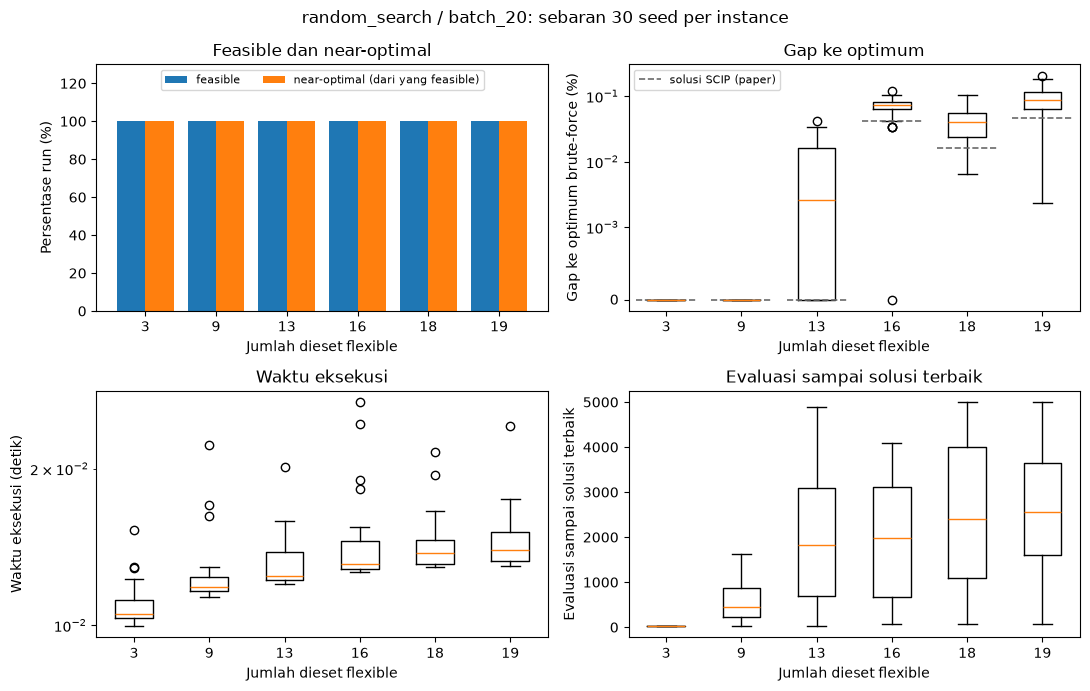

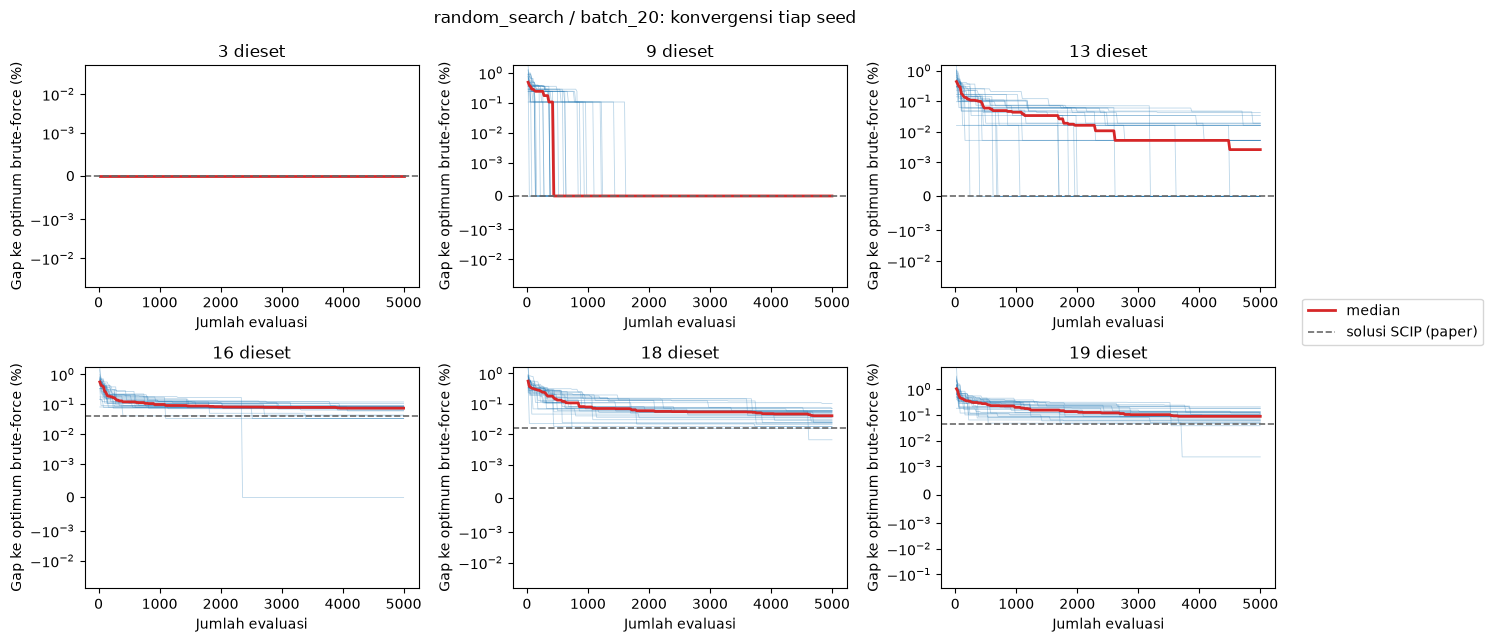

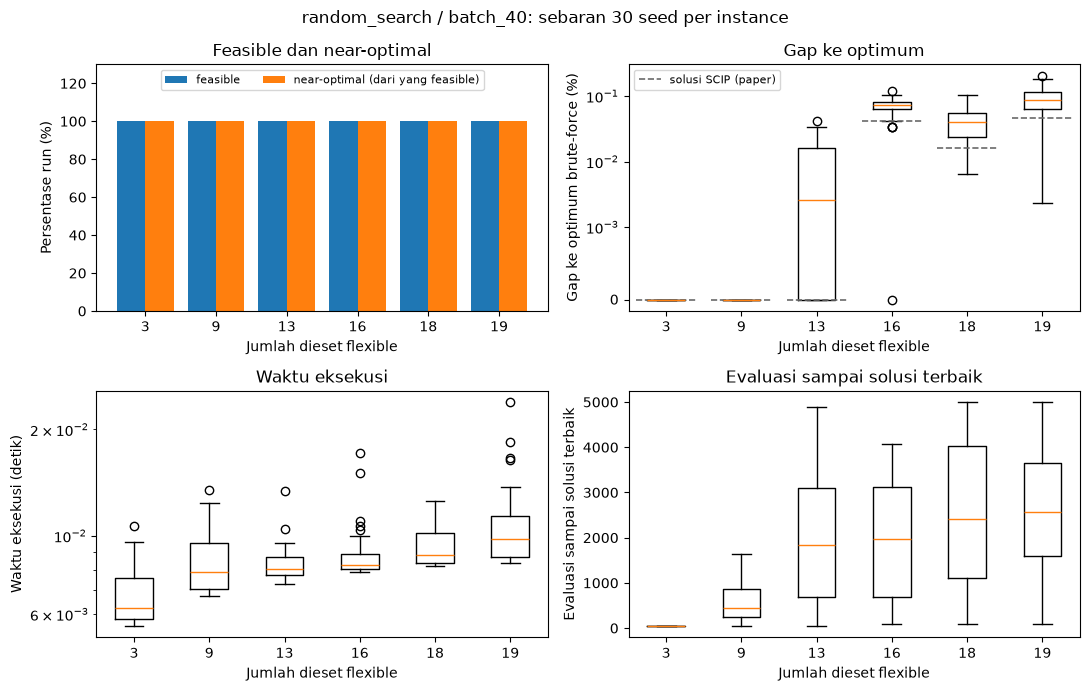

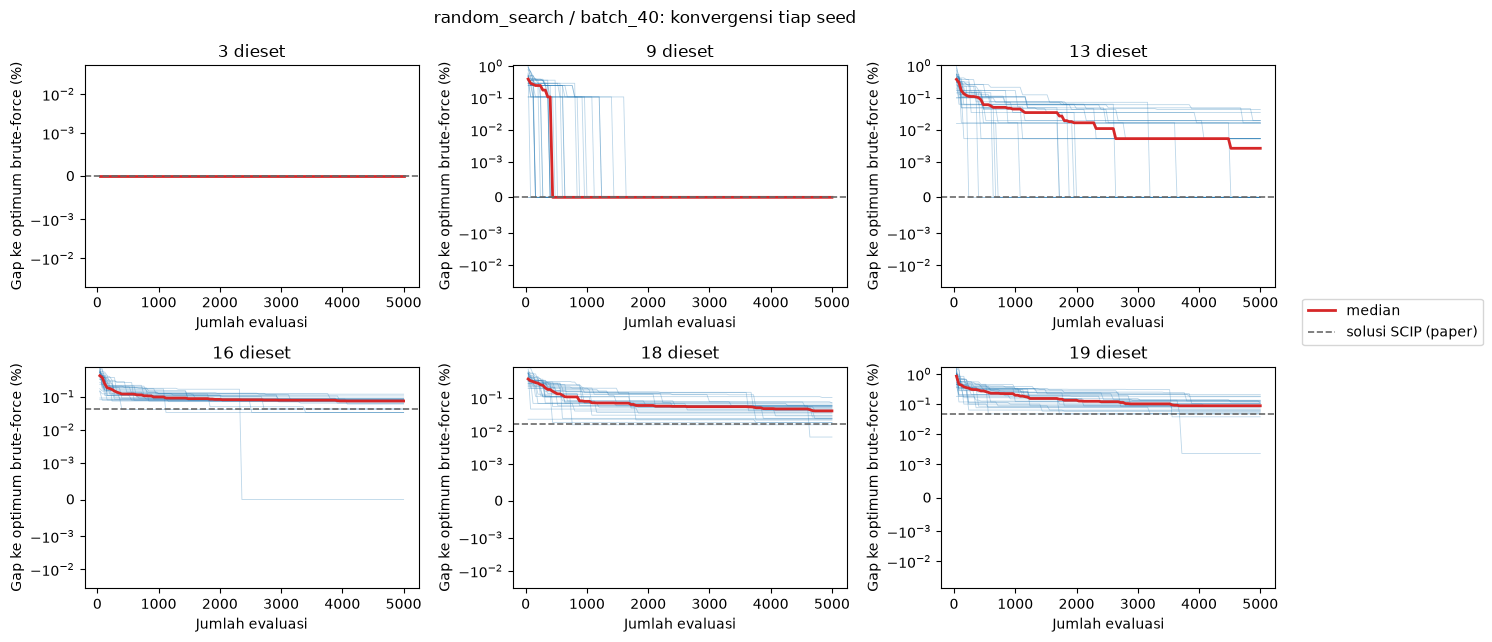

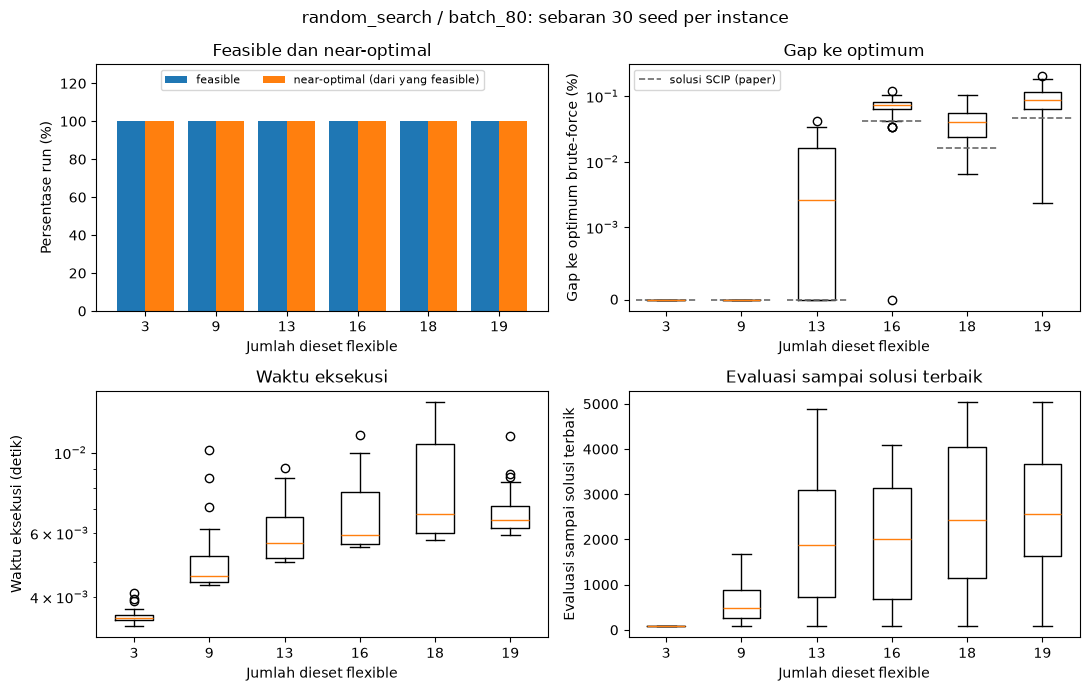

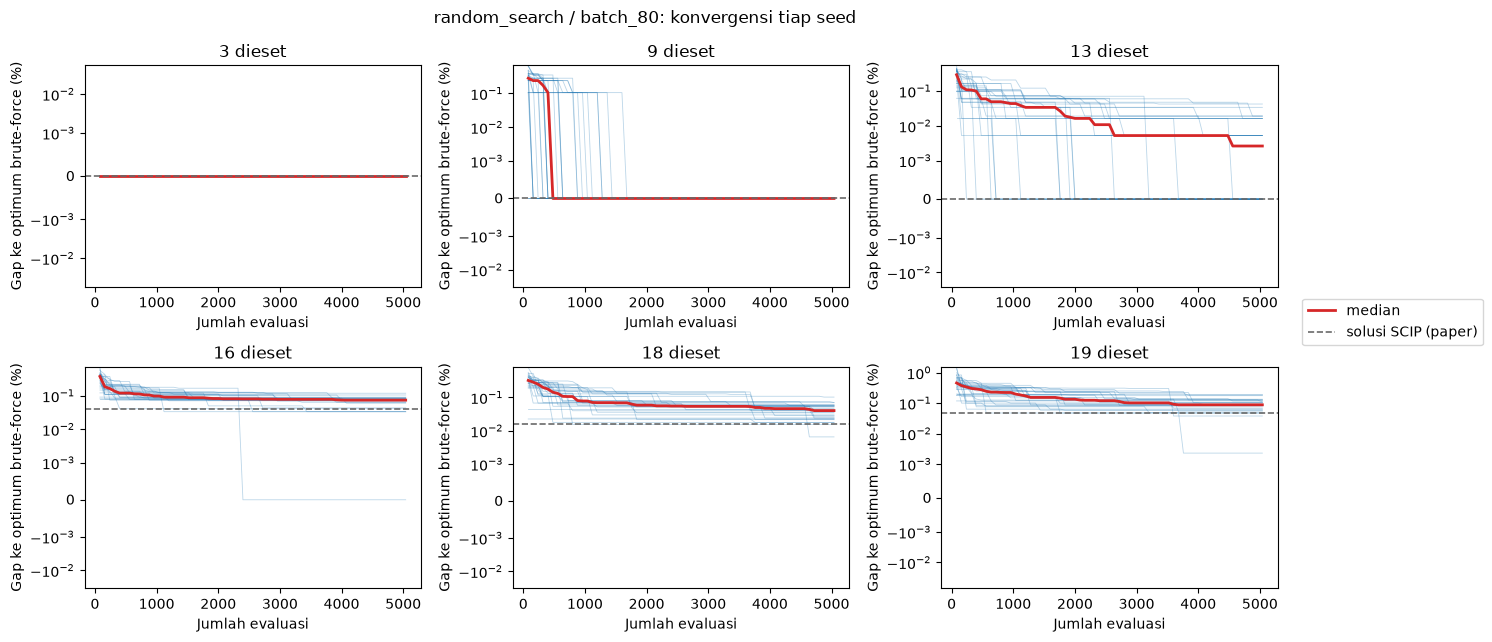

In [6]:
for config in CONFIGS:
    df = runs[runs.config == config]
    res = [r for r in results if r.config == config]

    fig = plots.plot_config_distribution(df, f"{ALGO} / {config}: sebaran {N_RUNS} seed per instance", OPTIMUM)
    plots.save_figure(fig, figure_dir / config / "distribution.png")
    plt.show()

    fig = plots.plot_seed_convergence(res, instances, f"{ALGO} / {config}: konvergensi tiap seed", OPTIMUM)
    plots.save_figure(fig, figure_dir / config / "convergence.png")
    plt.show()

## 6. Evaluasi antar konfigurasi

- Ranking: % feasible -> % near-optimal -> gap rata-rata (dirata-rata lintas instance). 

- Konfigurasi peringkat 1 dipakai di `comparison.ipynb`.

In [7]:
print("konfigurasi terbaik:", best_configs(ranking)[ALGO])
ranking.round(5)

konfigurasi terbaik: batch_20


,algorithm,config,rank,pct_feasible,pct_near_optimal,gap_mean,gap_max,pct_optimum_found,runtime_mean,iterations_to_best_mean,evaluations_to_best_mean
0,random_search,batch_20,1,100.0,100.0,0.03557,0.0784,42.22222,0.01338,79.74444,1614.88889
1,random_search,batch_40,2,100.0,100.0,0.03557,0.0784,42.22222,0.00889,39.67778,1627.11111
2,random_search,batch_80,3,100.0,100.0,0.03557,0.0784,42.22222,0.00608,19.62222,1649.77778


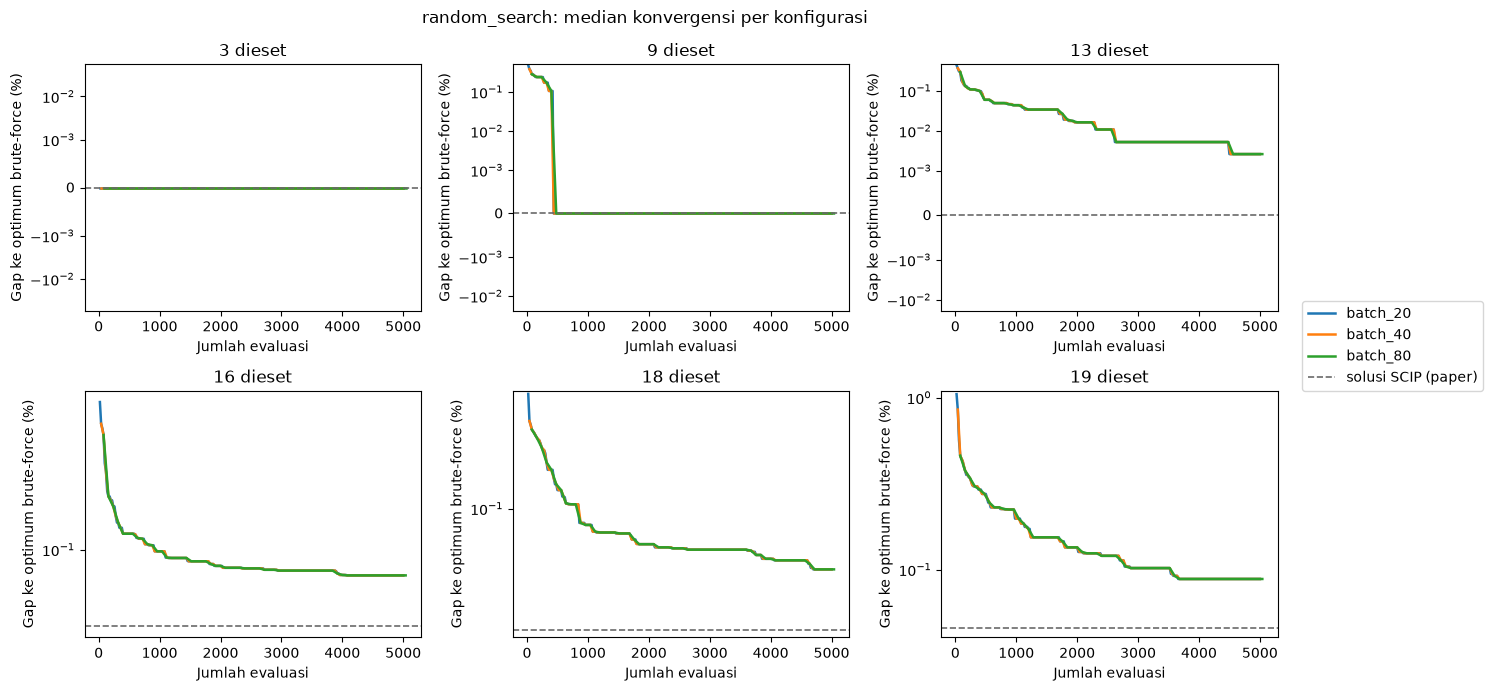

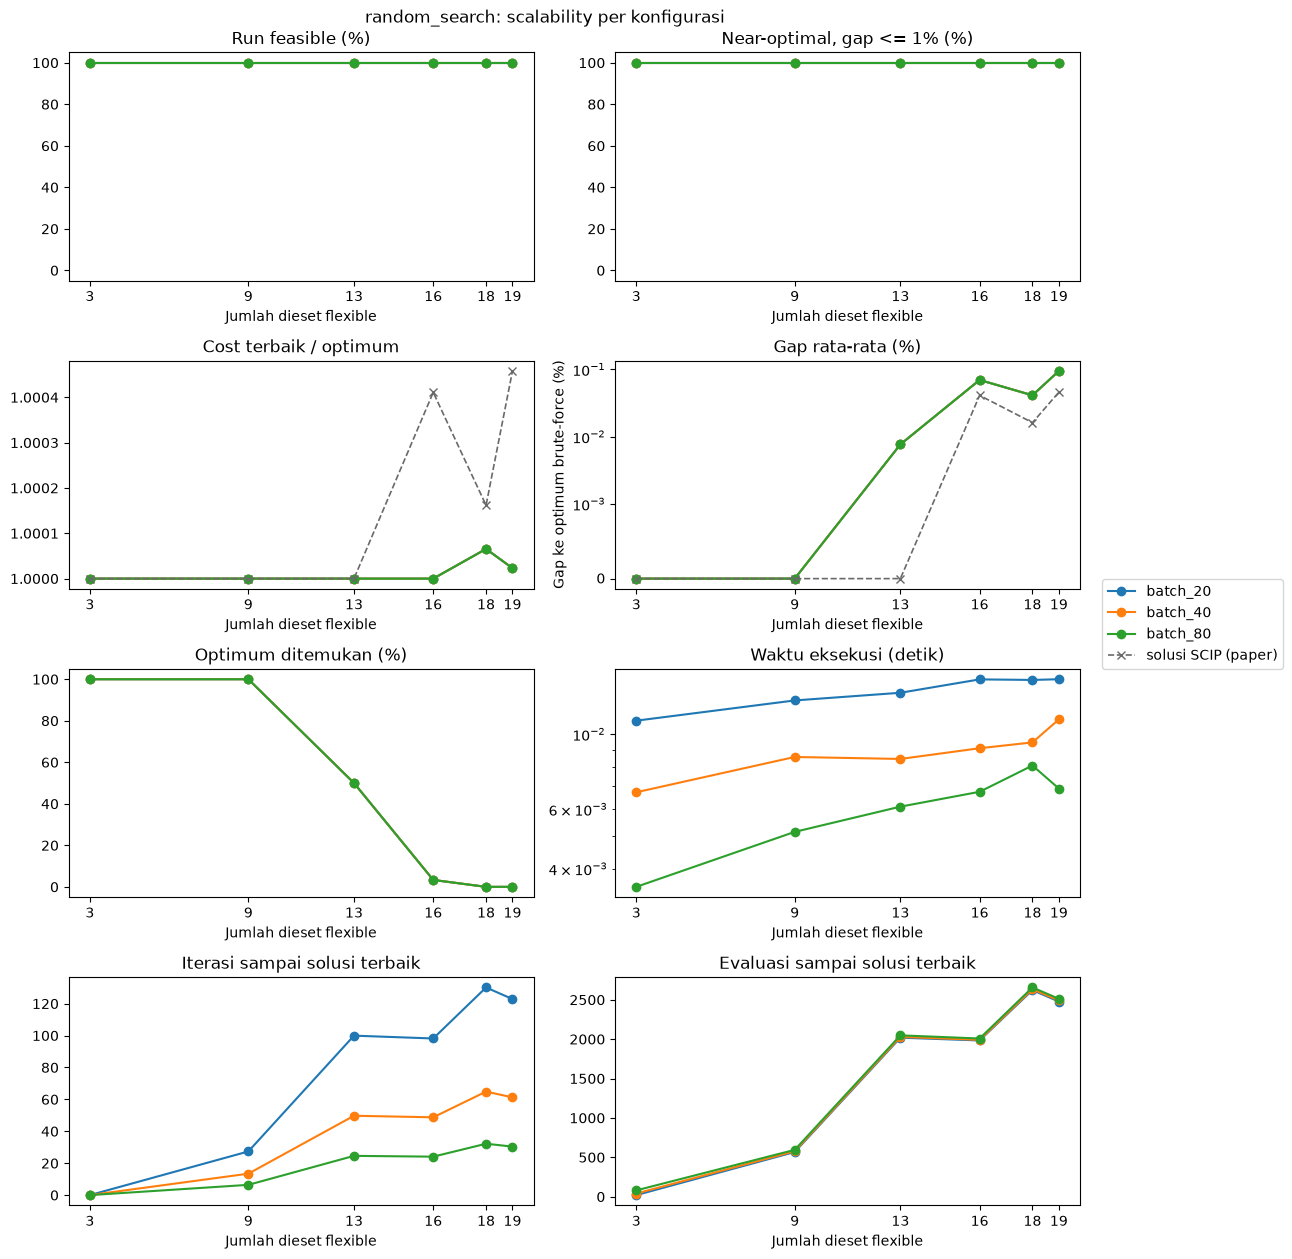

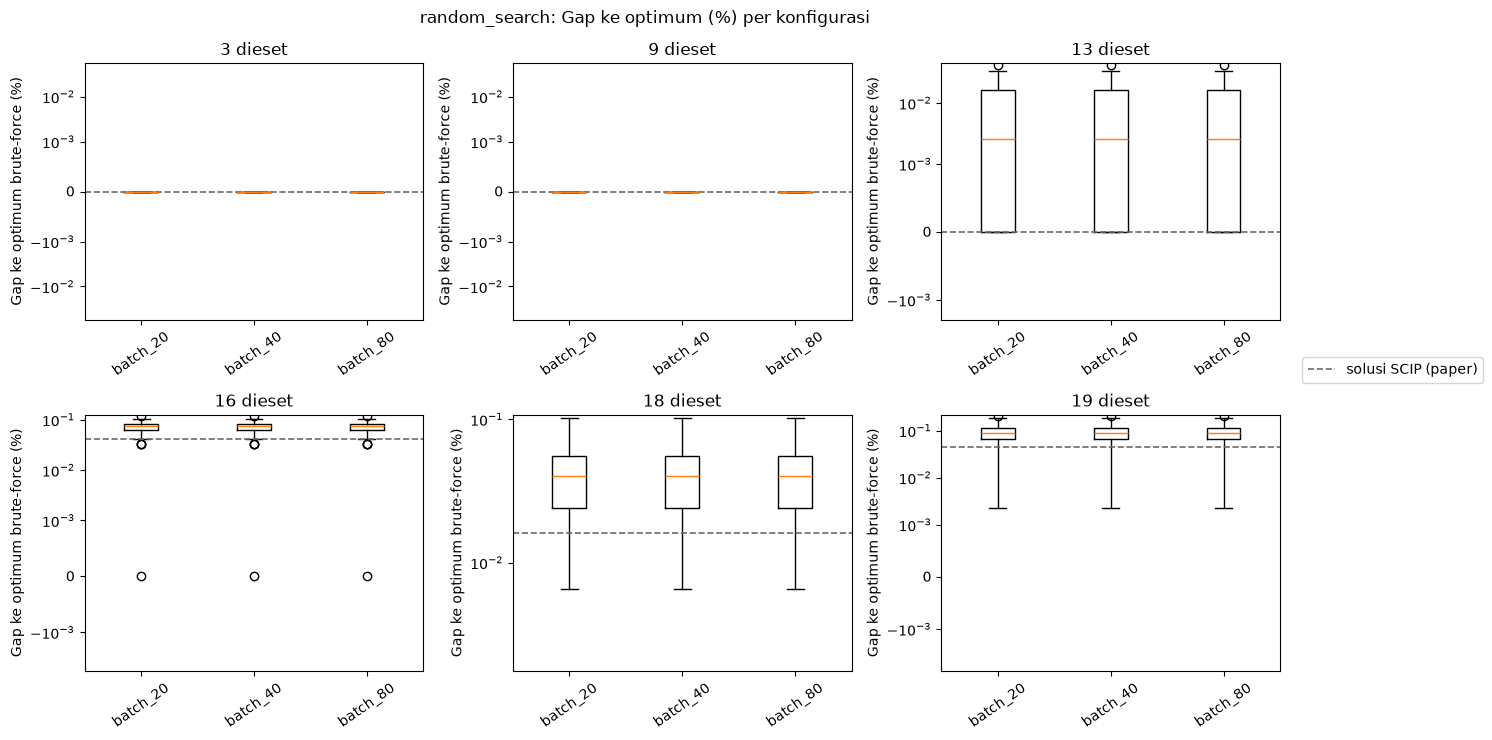

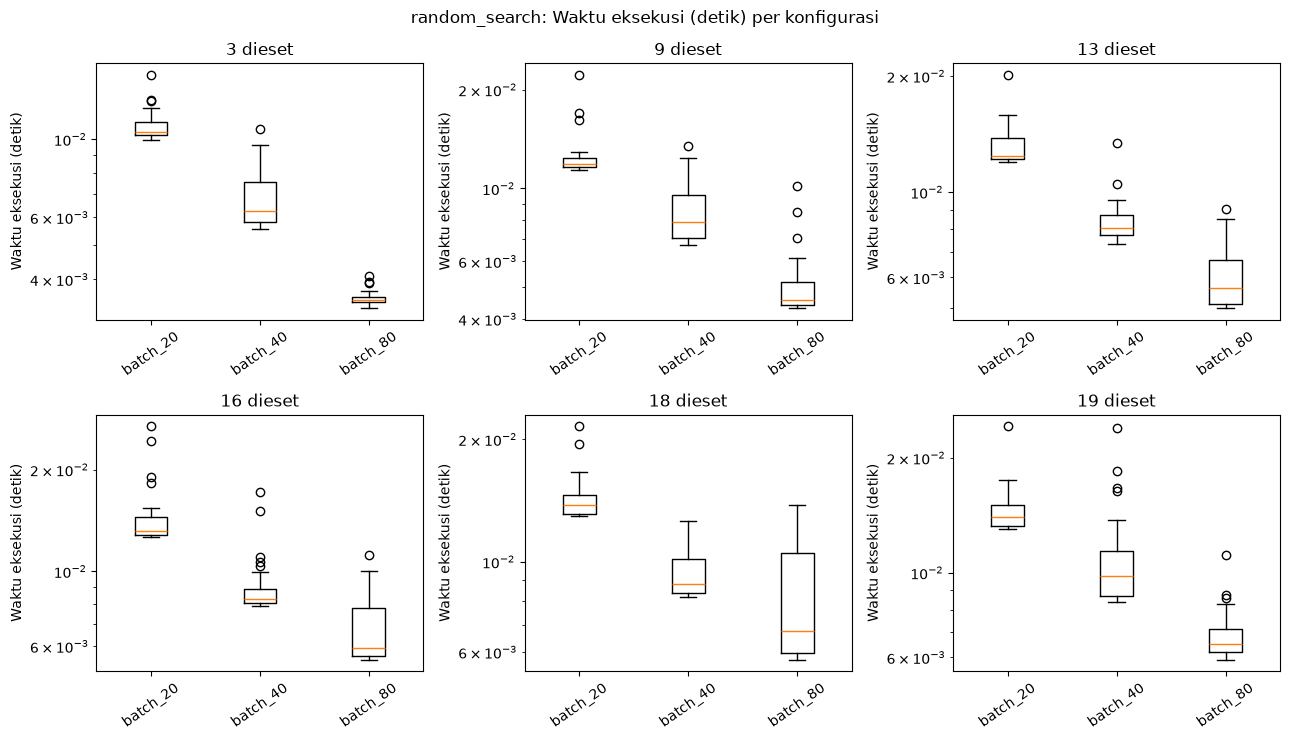

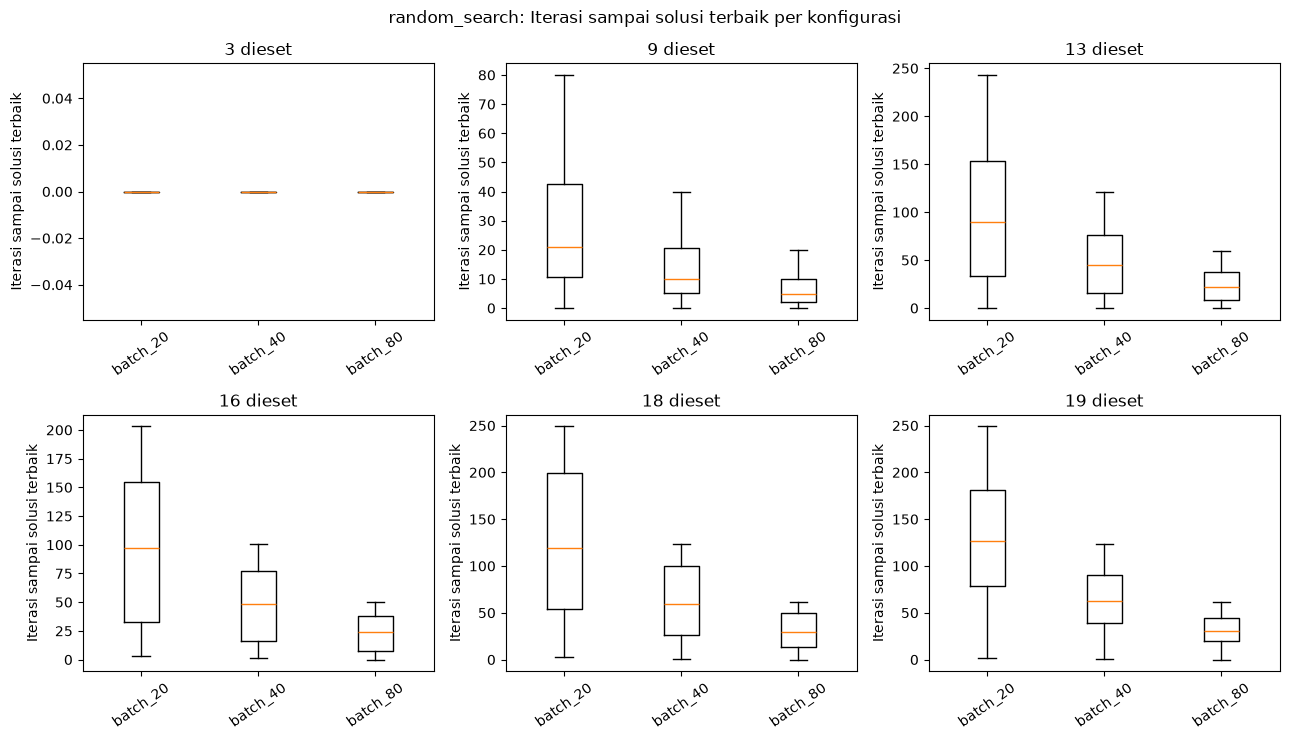

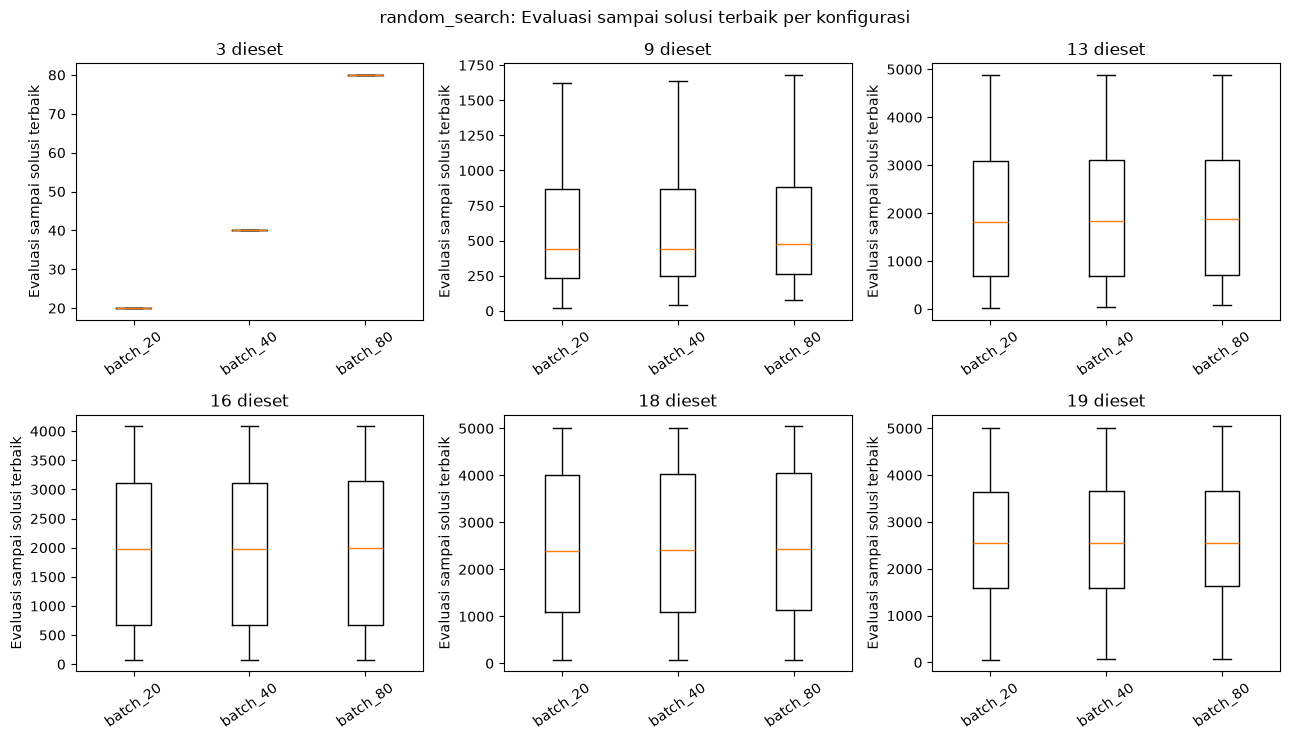

In [8]:
fig = plots.plot_group_convergence(results, instances, "config", f"{ALGO}: median konvergensi per konfigurasi", OPTIMUM)
plots.save_figure(fig, figure_dir / "configs_convergence.png")
plt.show()

fig = plots.plot_group_scalability(summary, "config", f"{ALGO}: scalability per konfigurasi", OPTIMUM)
plots.save_figure(fig, figure_dir / "configs_scalability.png")
plt.show()

for metric in ["gap_pct", "runtime_sec", "iterations_to_best", "evaluations_to_best"]:
    fig = plots.plot_group_distribution(runs, metric, "config", f"{ALGO}: {plots.LABELS[metric]} per konfigurasi", OPTIMUM)
    plots.save_figure(fig, figure_dir / f"configs_{metric}.png")
    plt.show()